# L1 · Primer contacto — Sesión 2: **Responder**
### Introducción a las Ciencias de la Computación · UNAL Manizales

En la sesión 1 recibieron un mensaje. Hoy escriben uno: su especie le va a hablar a otra especie del salón, que lo va a leer **sin instrucciones**, mientras el canal le daña bits al azar.

Al final de la sesión viene **el día del contacto**: los mensajes se reparten y cada equipo intenta leer uno ajeno con las herramientas que construyó la semana pasada.

In [ ]:
EQUIPO = ["Sebastian Bedoya","Jhoan Guacheta","Juan Cardenas","Juan Hernandez"]
MI_BASE = 6
NOMBRE_ESPECIE = "Tuhuy"

## Momento 1 — Predecir *(en papel)*

**P4.** ¿Qué fracción de su mensaje creen que la otra especie va a entender? Un número entre 0 y 1, y qué sección creen que se va a perder primero.

**P5.** Si el canal daña 1 de cada 100 bits, ¿cuántos bits dañados esperan en su mensaje? ¿Y si lo mandan tres veces?

✍️
- P4: Creo que entenderán 0,7 del mensaje. Lo más fácil será el conteo (primera parte) y la forma, porque se deducen del tamaño. Creo que perderán primero los pares (parte del medio), porque tienen un símbolo raro que no se entiende a la primera.
- P5:Mi mensaje tiene 323 bits. Si el canal daña 1 de cada 100, espero unos 3 bits dañados. Si lo mando 3 veces, los bits se multiplican por 3, así que los dañados también: 3 × 3 = 9 bits. (Al principio pensé que sería 3 a la 3, pero me equivoqué: al triplicar los bits, el daño se triplica.)

## 0. Sus herramientas

Peguen aquí **sus** funciones de la sesión 1 y de la tarea puente. Son suyas: se reutilizan, no se reescriben. Las pruebas de abajo verifican que llegaron completas.

In [ ]:
import matplotlib.pyplot as plt


def es_primo(n):
    """Devuelve True si n es primo."""
    if n < 2:
        return False
    d = 2
    while d * d <= n:
        if n % d == 0:
            return False
        d += 1
    return True


def rectangulos(n):
    """Devuelve la lista de pares (filas, columnas) con filas * columnas == n."""
    return [(f, n // f) for f in range(1, n + 1) if n % f == 0]


def filas_de(cadena, columnas):
    """Parte la cadena en pedazos de 'columnas' caracteres."""
    return [cadena[i:i + columnas] for i in range(0, len(cadena), columnas)]


def dibujar(bits, columnas):
    """Dibuja los bits en una cuadrícula: 1 = negro, 0 = blanco."""
    filas = filas_de(bits, columnas)
    matriz = [[int(c) for c in fila] for fila in filas]
    plt.figure(figsize=(columnas / 3 + 1, len(filas) / 3 + 1))
    plt.imshow(matriz, cmap="gray_r", interpolation="nearest")
    plt.axis("off")
    plt.show()


def leer_numero(lista_bits):
    """Lee una lista de 0/1 (el primero es el más significativo) como un entero en binario."""
    n = 0
    for b in lista_bits:
        n = 2 * n + b
    return n


def columna(bits, columnas, j, fila_desde, fila_hasta):
    """Lista de enteros 0/1 de la columna j, desde fila_desde hasta fila_hasta - 1."""
    return [int(bits[f * columnas + j]) for f in range(fila_desde, fila_hasta)]


def a_base_rec(n, b):
    """Dígitos de n en base b, el más significativo primero."""
    if n < b:
        return [n]
    return a_base_rec(n // b, b) + [n % b]


def de_base(digitos, b):
    """Convierte una lista de dígitos en base b a un entero."""
    n = 0
    for d in digitos:
        n = n * b + d
    return n

In [ ]:
# Pruebas de que las herramientas llegaron completas
assert es_primo(97) and not es_primo(1679)
assert rectangulos(12) == [(1, 12), (2, 6), (3, 4), (4, 3), (6, 2), (12, 1)]
assert filas_de("101100", 3) == ["101", "100"]
assert leer_numero([1, 0, 1, 1]) == 11
assert a_base_rec(1974, 6) == [1, 3, 0, 5, 0] and de_base([1, 3, 0, 5, 0], 6) == 1974
assert MI_BASE in (2, 3, 5, 6, 8, 12), "Escriban la base que les tocó."
print("✔ Herramientas listas. Especie de base", MI_BASE)

✔ Herramientas listas. Especie de base 6


## 1. ¿Cuántos bits por dígito?

Si cuentan en base 6, sus dígitos van de 0 a 5, y cada uno hay que escribirlo con bits. ¿Con cuántos? Es la desigualdad de la clase 3: con $k$ bits se escriben $2^k$ valores distintos, así que hace falta el menor $k$ con $2^k \geq b$.

- `bits_por_digito(b)` devuelve ese $k$.
- `digito_a_bits(d, ancho)` escribe un dígito con exactamente `ancho` bits, rellenando con ceros a la izquierda. Usen su `a_base_rec(d, 2)`.

In [ ]:
def bits_por_digito(b):
    """CONTRATO. Recibe una base b >= 2. Devuelve el menor k con 2**k >= b."""
    k = 1
    while 2 ** k < b:
        k += 1
    return k


def digito_a_bits(d, ancho):
    """CONTRATO. Recibe un entero 0 <= d < 2**ancho. Devuelve una cadena de exactamente
    'ancho' caracteres '0'/'1' con d en binario, rellenada con ceros a la izquierda."""
    binario = "".join(str(x) for x in a_base_rec(d, 2))
    return binario.zfill(ancho)

In [ ]:
# Pruebas
assert [bits_por_digito(b) for b in (2, 3, 5, 6, 8, 12)] == [1, 2, 3, 3, 3, 4]
assert digito_a_bits(5, 3) == "101" and digito_a_bits(1, 4) == "0001" and digito_a_bits(0, 2) == "00"
ANCHO = bits_por_digito(MI_BASE)
print("✔ Su especie escribe cada dígito con", ANCHO, "bits.")

✔ Su especie escribe cada dígito con 3 bits.


## 2. El mensaje, por secciones

**La representación del mensaje.** Un mensaje es una **lista de renglones**, y cada renglón es una cadena de `'0'` y `'1'` de exactamente `COLUMNAS` caracteres. Elijan `COLUMNAS` pensando en la pregunta de Arecibo: ¿cómo va a adivinar la otra especie el ancho del rectángulo?

Cada sección del mensaje es una **función** que devuelve una lista de renglones. Al final, `ensamblar` las pone una debajo de la otra. Si mañana quieren cambiar una sección, cambian una función y nada más: eso es pensar en módulos.

### La sección obligatoria: contar

`codificar_conteo(hasta)` escribe los números del 1 al `hasta` **en su base**, uno por renglón, cada dígito con `ANCHO` bits, alineados a la izquierda y rellenando el renglón con ceros. Ojo: deben contar al menos hasta un poco más allá de su base, para que se vea el momento en que aparece el "10".

In [ ]:
COLUMNAS = 17


def renglon(contenido):
    """CONTRATO. Recibe una cadena de bits de longitud <= COLUMNAS.
    Devuelve esa cadena rellenada con ceros a la derecha hasta COLUMNAS caracteres."""
    assert len(contenido) <= COLUMNAS, f"El renglón no cabe: {len(contenido)} > {COLUMNAS}"
    return contenido + "0" * (COLUMNAS - len(contenido))


def codificar_conteo(hasta):
    """CONTRATO. Devuelve una lista de renglones: el renglón i tiene el número i
    (de 1 a 'hasta') escrito en MI_BASE, cada dígito con ANCHO bits."""
    renglones = []
    for i in range(1, hasta + 1):
        digitos = a_base_rec(i, MI_BASE)
        bits = "".join(digito_a_bits(d, ANCHO) for d in digitos)
        renglones.append(renglon(bits))
    return renglones

✔ El conteo delata su base. Así se ve:


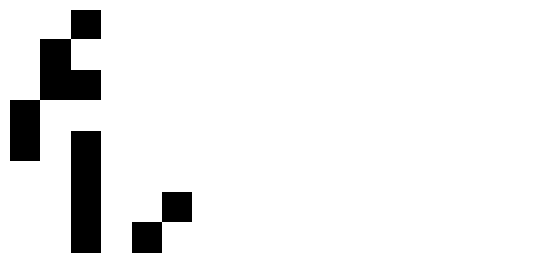

In [ ]:
# Pruebas
conteo = codificar_conteo(MI_BASE + 2)
assert len(conteo) == MI_BASE + 2 and all(len(r) == COLUMNAS for r in conteo)
assert conteo[0].startswith(digito_a_bits(1, ANCHO))
assert conteo[MI_BASE - 1].startswith(digito_a_bits(1, ANCHO) + digito_a_bits(0, ANCHO)), "El renglón de MI_BASE debe decir '10'."
print("✔ El conteo delata su base. Así se ve:")
dibujar("".join(conteo), COLUMNAS)

### Sus secciones

Una función por sección, cada una con su contrato. Copien la plantilla tantas veces como secciones tengan.

In [ ]:
def codificar_seccion_2():
    """CONTRATO. Qué dice: pares (n, n al cuadrado), separados por un símbolo
    que no es un dígito de la base.
    Devuelve: lista de renglones de COLUMNAS bits."""
    renglones = []
    separador = "1" * ANCHO    # 111 = 7, y en base 6 no existe el dígito 7
    for n in range(1, 5):
        izquierda = "".join(digito_a_bits(d, ANCHO) for d in a_base_rec(n, MI_BASE))
        derecha = "".join(digito_a_bits(d, ANCHO) for d in a_base_rec(n * n, MI_BASE))
        renglones.append(renglon(izquierda + separador + derecha))
    return renglones


def codificar_seccion_3():
    """CONTRATO. Qué dice: un dibujo, una cara.
    Devuelve: lista de renglones de COLUMNAS bits."""
    dibujo = [
        "..#####..",
        ".#.....#.",
        "#..#.#..#",
        "#.......#",
        "#.#...#.#",
        ".#.###.#.",
        "..#####..",
    ]
    renglones = []
    for linea in dibujo:
        bits = linea.replace("#", "1").replace(".", "0")
        renglones.append(renglon(bits))
    return renglones

Longitud del mensaje: 323 bits
Formas de dibujarlo: [(1, 323), (17, 19), (19, 17), (323, 1)]


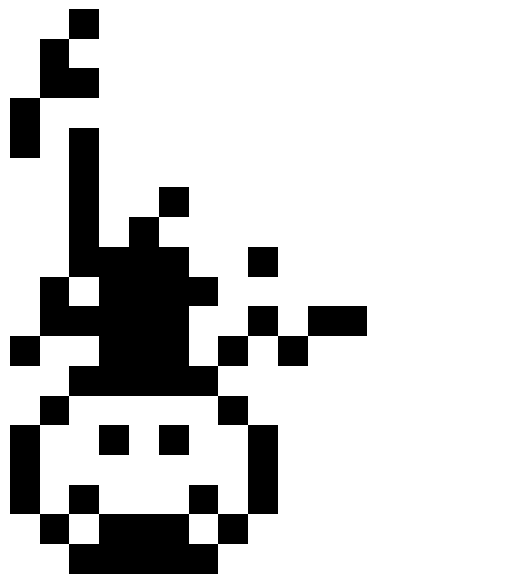

In [ ]:
def ensamblar(secciones):
    """CONTRATO. Recibe una lista de secciones (cada una, una lista de renglones).
    Devuelve una sola cadena de bits: todos los renglones, uno detrás de otro."""
    cadena = ""
    for seccion in secciones:
        for r in seccion:
            cadena += r
    return cadena


mensaje = ensamblar([codificar_conteo(MI_BASE + 2), codificar_seccion_2(), codificar_seccion_3()])
print("Longitud del mensaje:", len(mensaje), "bits")
print("Formas de dibujarlo:", rectangulos(len(mensaje)))
dibujar(mensaje, COLUMNAS)

### La forma

¿Su mensaje tiene una longitud que obligue a **una sola** manera de dibujarlo, como Arecibo? Si no, agreguen renglones de relleno hasta que el número de renglones lo permita. Pista: si `COLUMNAS` es primo y el número de renglones también, solo hay dos rectángulos posibles (y uno es el traspuesto del otro). Escriban `es_semiprimo(n)` con su `rectangulos` si les sirve.

In [ ]:
def es_semiprimo(n):
    """CONTRATO. True si n es el producto de dos primos."""
    for a in range(2, n):
        if n % a == 0 and es_primo(a) and es_primo(n // a):
            return True
    return False


filas = len(mensaje) // COLUMNAS
print("Columnas:", COLUMNAS, "| Renglones:", filas)
print("¿Columnas primo?", es_primo(COLUMNAS), "| ¿Renglones primo?", es_primo(filas))
print("¿Semiprimo?", es_semiprimo(len(mensaje)))
print("Formas de dibujarlo:", rectangulos(len(mensaje)))

Columnas: 17 | Renglones: 19
¿Columnas primo? True | ¿Renglones primo? True
¿Semiprimo? True
Formas de dibujarlo: [(1, 323), (17, 19), (19, 17), (323, 1)]


## 3. Las preguntas incómodas de la representación

Su mensaje tiene que responder **al menos dos** de estas. En cada una, escriban cómo lo resolvieron (o por qué no se puede).

1. **Ancho fijo.** Si cada número va en un renglón de `COLUMNAS` bits, ¿cuál es el número más grande que cabe en su base? ¿Qué pasa si quieren decir cuántos habitantes tiene Manizales? A esto se le llama **desbordamiento**.
2. **Decimales.** ¿Cómo dicen la altura de Manizales en metros si el otro no sabe qué es un metro, ni dónde va la coma? *(Pista real: en 1972, las placas de las sondas Pioneer usaron una propiedad del átomo de hidrógeno como regla para medir, porque el hidrógeno es igual en todo el universo.)*
3. **Texto.** ¿Por qué no pueden mandar la palabra "Manizales" en ASCII o en Unicode? ¿Qué **sí** pueden mandar?
4. **Forma.** ¿Cómo va a saber la otra especie cuántas columnas tiene su mensaje?

In [ ]:
digitos_por_renglon = COLUMNAS // ANCHO
maximo = MI_BASE ** digitos_por_renglon - 1
print("Dígitos por renglón:", digitos_por_renglon)
print("Número más grande que cabe:", maximo)

Dígitos por renglón: 5
Número más grande que cabe: 7775


✍️
1. Ancho fijo. En un renglón caben 5 dígitos y el número más grande que cabe en base 6 es 7775. Manizales tiene más de 400 000 habitantes, así que el número se desborda. Lo vimos al mirar el código y al buscar cuántos habitantes tiene. Para decirlo igual, lo diría en miles: mandaría 400 y el otro tendría que deducir que cada unidad vale mil.

2. Decimales. No puedo usar el metro porque el otro no sabe qué es. Dibujaría una persona al lado como comparación y diría la altura como cuántas veces cabe esa persona. Para la coma, diría cuántos dígitos van después de ella, así el otro sabe dónde va.

3. Texto. No puedo mandar "Manizales" en ASCII o Unicode porque son acuerdos entre humanos y el otro no tiene esa tabla. Lo que sí puedo mandar sin ningún acuerdo previo son dibujos y números.

4. Forma. El otro no sabe cuántas columnas tiene. Puede probar las formas posibles con rectangulos y quedarse con la que dibuja algo con sentido. Mi mensaje original mide 323 bits, que solo se reparte como 17 × 19; el que mandé, con paridad, mide 342 y tiene más formas posibles, así que tendrá que probar varias.

## 4. El canal

Entre las estrellas el mensaje se daña: la radiación voltea bits. Vamos a simular ese canal y a comparar **dos maneras** de proteger el mensaje.

- `ruido(bits, p)`: voltea cada bit con probabilidad `p` (usen `random.random() < p`).
- **Manera 1, paridad.** `con_paridad(bits, ancho)` agrega a cada renglón un bit extra para que el número de unos del renglón sea **par**. Del otro lado, `filas_danadas(bits, ancho)` dice qué renglones llegaron con número impar de unos. (Ojo: el ancho de cada renglón ahora es `ancho + 1`.)
- **Manera 2, repetición.** `repetir3(bits)` manda cada bit tres veces seguidas; `votar(bits)` toma cada grupo de tres y se queda con el que más aparece.

In [ ]:
import random


def ruido(bits, p):
    """CONTRATO. Devuelve una copia de bits donde cada bit se volteó con probabilidad p."""
    salida = ""
    for c in bits:
        if random.random() < p:
            salida += "1" if c == "0" else "0"
        else:
            salida += c
    return salida


def con_paridad(bits, ancho):
    """CONTRATO. Parte bits en renglones de 'ancho' y a cada uno le agrega un bit de paridad
    al final, de modo que cada renglón (ahora de ancho + 1) tenga un número par de unos."""
    salida = ""
    for i in range(0, len(bits), ancho):
        r = bits[i:i + ancho]
        paridad = "1" if r.count("1") % 2 == 1 else "0"
        salida += r + paridad
    return salida


def filas_danadas(bits, ancho):
    """CONTRATO. Recibe bits con paridad, en renglones de ancho + 1.
    Devuelve la lista de índices de los renglones con un número impar de unos."""
    paso = ancho + 1
    malas = []
    for k in range(len(bits) // paso):
        r = bits[k * paso:(k + 1) * paso]
        if r.count("1") % 2 == 1:
            malas.append(k)
    return malas


def repetir3(bits):
    """CONTRATO. Devuelve bits con cada carácter repetido tres veces seguidas."""
    salida = ""
    for c in bits:
        salida += c * 3
    return salida


def votar(bits):
    """CONTRATO. Recibe una cadena de longitud múltiplo de 3. Por cada grupo de tres,
    devuelve el bit que aparece al menos dos veces."""
    salida = ""
    for i in range(0, len(bits), 3):
        grupo = bits[i:i + 3]
        salida += "1" if grupo.count("1") >= 2 else "0"
    return salida

In [ ]:
# Pruebas
random.seed(0)
assert ruido("0101", 0) == "0101" and ruido("0101", 1) == "1010"
assert con_paridad("110100", 3) == "11001001"
assert filas_danadas("11001001", 3) == [] and filas_danadas("11011001", 3) == [0]
assert repetir3("10") == "111000" and votar("110001") == "10" and votar(repetir3("1011")) == "1011"
print("✔ El canal y las dos protecciones pasan las pruebas.")

✔ El canal y las dos protecciones pasan las pruebas.


### Medir, no suponer

Corran el canal **mil veces** con `p = 0.01` sobre su mensaje y cuenten:

- **Paridad:** ¿en cuántas transmisiones hubo al menos un error? ¿En cuántas `filas_danadas` lo detectó? ¿En cuántas hubo errores que **no** detectó? (¿Cómo puede pasar eso?)
- **Repetición:** ¿en cuántas transmisiones `votar` recuperó el mensaje **exacto**?
- ¿Cuántos bits cuesta cada manera, comparado con el mensaje original?

In [ ]:
N = 1000
p = 0.01

con_error = detectadas = no_detectadas = 0
recuperadas_rep = 0

for _ in range(N):
    # Paridad
    protegido = con_paridad(mensaje, COLUMNAS)
    recibido = ruido(protegido, p)
    if recibido != protegido:
        con_error += 1
        if filas_danadas(recibido, COLUMNAS):
            detectadas += 1
        else:
            no_detectadas += 1

    # Repetición
    recibido_rep = ruido(repetir3(mensaje), p)
    if votar(recibido_rep) == mensaje:
        recuperadas_rep += 1

print("Paridad   : con error", con_error, "| detectadas", detectadas, "| sin detectar", no_detectadas)
print("Repetición: recuperadas exactas", recuperadas_rep, "de", N)
print("Costo en bits: original", len(mensaje), "| paridad", len(con_paridad(mensaje, COLUMNAS)),
      "| repetición", len(repetir3(mensaje)))

Paridad   : con error 972 | detectadas 966 | sin detectar 6
Repetición: recuperadas exactas 904 de 1000
Costo en bits: original 323 | paridad 342 | repetición 969


✍️ **¿Cuál de las dos protecciones elegirían para un mensaje que tarda 25 000 años en llegar, y por qué? Elegiría la paridad porque cuesta pocos bits: 342 contra 969 de la repetición. En mis mediciones detectó 966 de 972 errores. Sé que no corrige y que en 25 000 años nadie puede pedir que reenvíen, así que un renglón dañado se sabría cuál es pero no se arreglaría. Acepto ese riesgo por el costo.

## 5. Mandar el mensaje

Elijan su protección, pasen el mensaje por el canal **una sola vez** con `p = 0.01` y guárdenlo en `mensaje.txt`: una sola línea de ceros y unos, **sin** decir cuántas columnas tiene ni qué protección usaron. Entréguenle el archivo al monitor. Súbanlo también a su repositorio.

In [ ]:
PROTECCION = "paridad"      # o "repeticion"

if PROTECCION == "paridad":
    enviado = ruido(con_paridad(mensaje, COLUMNAS), 0.01)
else:
    enviado = ruido(repetir3(mensaje), 0.01)

with open("mensaje.txt", "w") as f:
    f.write(enviado)
print("mensaje.txt listo:", len(enviado), "bits. Entréguenlo al monitor.")

mensaje.txt listo: 342 bits. Entréguenlo al monitor.


## 6. El día del contacto

El monitor les entrega el `mensaje.txt` de **otra especie**. Tienen 30 minutos para leerlo **con sus herramientas de la sesión 1**: `len`, `rectangulos`, `dibujar`, `columna`, `leer_numero`, `de_base`. Si sirven para un mensaje que nunca habían visto, eran herramientas de verdad; si solo servían para Arecibo, eran un truco.

Súbanlo a Colab (ícono de carpeta → subir) con el nombre `recibido.txt`.

In [ ]:
with open("recibido.txt") as f:
    ajeno = f.read().strip()

print("Longitud:", len(ajeno))
print("Formas posibles:", rectangulos(len(ajeno)))
# Sigan ustedes: dibujen, busquen el conteo, deduzcan la base...

Longitud: 1311
Formas posibles: [(1, 1311), (3, 437), (19, 69), (23, 57), (57, 23), (69, 19), (437, 3), (1311, 1)]


Grupos de 3 iguales: 422 de 437
437


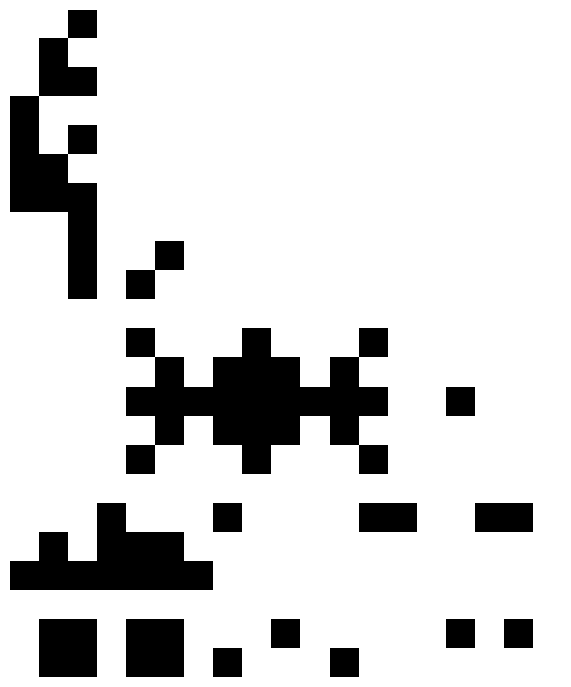

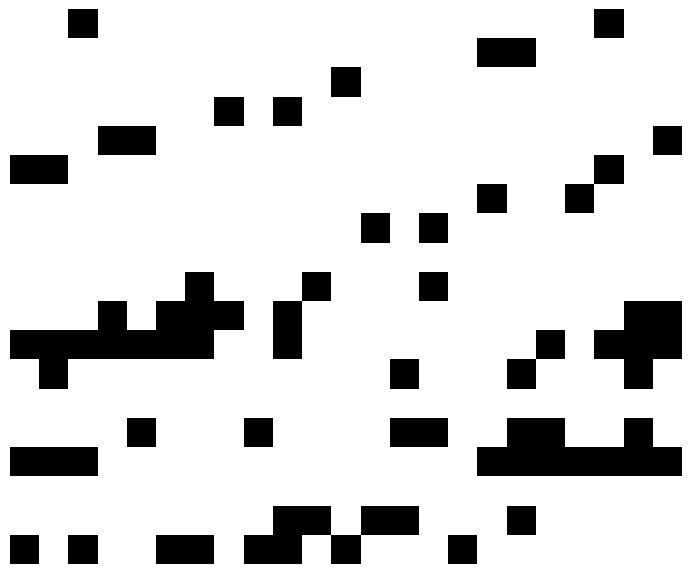

In [ ]:
grupos = [ajeno[i:i + 3] for i in range(0, len(ajeno), 3)]
iguales = sum(1 for g in grupos if g in ("000", "111"))
print("Grupos de 3 iguales:", iguales, "de", len(grupos))

original = votar(ajeno)
print(len(original))
for c in (19, 23):
    dibujar(original, c)

✍️ **Lo que entendimos del mensaje de la otra especie :**

- Ancho que dedujimos: 19 columnas, porque el mensaje tiene 1311 bits (3 × 19 × 23); al quitar la repetición quedan 437 bits (19 × 23), y con 19 columnas las figuras se ven alineadas, mientras que con 23 se ve como ruido.
- Base que dedujimos: 8, porque el conteo de arriba va 1, 2, 3, 4, 5, 6, 7 y luego vuelve a empezar con 10, 11, 12. El último dígito es el 7, y 7 + 1 = 8. Cada dígito usa 3 bits, que da justo 8 valores (0 a 7).
- Protección que creemos que usaron: repetición, porque 422 de 437 grupos de tres bits eran iguales (000 o 111), y al votar queda el mensaje de 437 bits.
- Lo que dice cada sección:
  1. Parece un conteo en binario, con números que van aumentando.
  2. Una figura con forma de cruz o tridente. No sé qué representa.
  3. Cuadritos sueltos. No logramos entender qué dicen.

## 7. La revelación

Cada especie lee en voz alta lo que entendió del mensaje que recibió, y la especie emisora revela su contrato de lectura. Anoten **de su propio mensaje**:

| Paso de nuestro contrato de lectura | ¿Lo dio la otra especie? | Si no, ¿por qué? |
|---|---|---|
| | | |
| | | |
| | | |

¿Hubo algo que la otra especie entendió **mal**, con toda seguridad? (Recuerden la palabra "arma" en *La llegada*.)

## Momento 3 — Explicar *(una página por equipo)*

1. **Confronten P4** con lo que de verdad se entendió de su mensaje. ¿Por qué la diferencia?
2. **La convención escondida:** ¿qué supusieron **sin darse cuenta** que la otra especie no tenía?
3. **Paridad contra repetición:** cuál eligieron y por qué, con las mediciones de la sección 4.
4. Una frase que empiece por *"Representar es..."*. Compárenla con la de la sesión 1: ¿cambió?

✍️

## La IA como objeto de estudio *(para la bitácora individual)*

Denle a su asistente el `mensaje.txt` de **otra especie** del salón (no el suyo), sin decirle nada más, y pídanle que lo traduzca. Ese mensaje no está en ningún lugar de internet: no lo puede reconocer, solo lo puede descifrar.

Comparen lo que dice el asistente con lo que reveló la especie emisora. ¿Tradujo con seguridad algo que no estaba ahí? Esa es la escena del "arma", y la acaban de medir. Y vuelvan a la pregunta de la sesión 1: ¿qué hizo con Arecibo, descifrar o reconocer?

## Foto de las predicciones

`foto_predicciones_sesion2.jpg`

---
### Antes de irse
1. **Ejecuten todo de arriba a abajo** (*Entorno de ejecución → Reiniciar y ejecutar todo*). Si algo falla, no está terminado.
2. **Guarden una copia en su repositorio `intro-cc`:** *Archivo → Guardar una copia en GitHub*. Cada integrante en el suyo.
3. La **bitácora de IA** es individual y va aparte (la plantilla es `bitacora_IA_L1.md`, en la carpeta `introduccion_cc` del repositorio de laboratorios).